In [46]:
# ==========================================
# PHASE 1 — Setup, Data Loading & Preprocessing (Fixed Column Name)
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

print("Libraries imported successfully.")

# Path pointing directly to your './data' folder
data_dir = "./data"

if not os.path.exists(data_dir):
    raise FileNotFoundError(f"Folder '{data_dir}' nahi mila!")
else:
    print(f"Data directory successfully detected at '{data_dir}'.")

# [3] Load & preprocess directly from ./data/
ratings_path = os.path.join(data_dir, "u.data")
df_ratings = pd.read_csv(ratings_path, sep='\t', names=['user_id', 'item_id', 'rating', 'timestamp'])

users_path = os.path.join(data_dir, "u.user")
df_users = pd.read_csv(users_path, sep='\|', engine='python', names=['user_id', 'age', 'gender', 'occupation', 'zip_code'])

genre_cols = [
    'unknown', 'Action', 'Adventure', 'Animation', 'Children\'s', 'Comedy', 
    'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 
    'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
]
items_path = os.path.join(data_dir, "u.item")
df_items = pd.read_csv(items_path, sep='\|', engine='python', encoding='latin-1', names=['movie_id', 'movie_title', 'release_date', 'video_release_date', 'IMDb_URL'] + genre_cols)

# Filter inactive users (<5 ratings)
user_counts = df_ratings['user_id'].value_counts()
active_users = user_counts[user_counts >= 5].index
df_ratings = df_ratings[df_ratings['user_id'].isin(active_users)]

# Extract gender mapping (M: Male, F: Female)
user_gender = df_users.set_index('user_id')['gender'].to_dict()
df_ratings['gender'] = df_ratings['user_id'].map(user_gender)

# Map original IDs to contiguous indices (Using 'item_id' for ratings and 'movie_id' for items)
user_ids = df_ratings['user_id'].unique()
item_ids = df_items['movie_id'].unique()

user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {it: i for i, it in enumerate(item_ids)}

df_ratings['user_idx'] = df_ratings['user_id'].map(user2idx)
df_ratings['item_idx'] = df_ratings['item_id'].map(item2idx)

n_users = len(user_ids)
n_items = len(item_ids)

# Filter items dataframe to match active item mappings
df_items_filtered = df_items[df_items['movie_id'].isin(df_ratings['item_id'])].sort_values('movie_id')
item_genres = df_items_filtered[genre_cols].values # Shape: (n_items, n_genres)

print(f"Processed Data: {n_users} users, {n_items} items, {len(df_ratings)} interactions.")

Libraries imported successfully.
Data directory successfully detected at './data'.
Processed Data: 943 users, 1682 items, 100000 interactions.


In [47]:
# Train/test split (80/20) per user or globally
train_df, test_df = train_test_split(df_ratings, test_size=0.2, random_state=42)

# Build user interaction history for BPR / Evaluation
user_positive_items = train_df[train_df['rating'] >= 3].groupby('user_idx')['item_idx'].apply(list).to_dict()
#here key is user idx and value is list of movies the user liked (jin jin movies ko rating >=3 mili hai )
# Map user indices to genders ('M' / 'F')
idx2user_gender = {user2idx[u]: user_gender[u] for u in user_ids if u in user2idx}
# this creates pytorch vae user idx to gender ki mapping 
male_users = [u for u, g in idx2user_gender.items() if g == 'M']# male users ki id
female_users = [u for u, g in idx2user_gender.items() if g == 'F']# female users ki id

In [48]:
# ==========================================
# PHASE 2 — Baseline MF Model (No Fairness) - Fixed
# ==========================================

import torch.nn.functional as F

class BPRDataframeDataset(Dataset):
    def __init__(self, df, n_items):
        self.users = df['user_idx'].values
        self.items = df['item_idx'].values
        self.n_items = n_items
        # Create user positive sets for negative sampling
        self.user_positives = df.groupby('user_idx')['item_idx'].apply(set).to_dict()
        
    def __len__(self):
        return len(self.users)
        
    def __getitem__(self, idx):
        u = self.users[idx]
        i = self.items[idx]
        # Sample a negative item
        j = np.random.randint(self.n_items)
        while j in self.user_positives.get(u, set()):
            j = np.random.randint(self.n_items)
        return torch.tensor(u, dtype=torch.long), torch.tensor(i, dtype=torch.long), torch.tensor(j, dtype=torch.long)

class MatrixFactorizationBPR(nn.Module):
    def __init__(self, n_users, n_items, latent_dim=32):
        super(MatrixFactorizationBPR, self).__init__()
        self.user_emb = nn.Embedding(n_users, latent_dim)
        self.item_emb = nn.Embedding(n_items, latent_dim)
        
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
        
    def forward(self, u, i, j):
        u_e = self.user_emb(u) # (B, dim)
        i_e = self.item_emb(i) # (B, dim)
        j_e = self.item_emb(j) # (B, dim)
        
        x_ui = (u_e * i_e).sum(dim=-1)
        x_uj = (u_e * j_e).sum(dim=-1)
        return x_ui, x_uj

def train_bpr_model(model, dataset, epochs=5, lr=0.01, batch_size=256):
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for u, i, j in dataloader:
            optimizer.zero_grad()
            x_ui, x_uj = model(u, i, j)
            loss = -torch.mean(F.logsigmoid(x_ui - x_uj))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs} | BPR Loss: {total_loss/len(dataloader):.4f}")

# Train baseline model
latent_dim = 32
baseline_mf = MatrixFactorizationBPR(n_users, n_items, latent_dim=latent_dim)
train_dataset = BPRDataframeDataset(train_df, n_items)

print("Training Baseline MF Model...")
train_bpr_model(baseline_mf, train_dataset, epochs=5, lr=0.01)

Training Baseline MF Model...
Epoch 1/5 | BPR Loss: 0.4362
Epoch 2/5 | BPR Loss: 0.2593
Epoch 3/5 | BPR Loss: 0.2114
Epoch 4/5 | BPR Loss: 0.1852
Epoch 5/5 | BPR Loss: 0.1654


In [ ]:
# Evaluation Metrics Setup (Top-K Recommendations, K=10)
def generate_top_k_recs(model, user_ids, n_items, k=50, exclude_history=None):
    model.eval()
    recommendations = {}
    with torch.no_grad():
        all_items = torch.arange(n_items)
        for u in user_ids:
            u_tensor = torch.tensor([u] * n_items, dtype=torch.long)
            i_tensor = all_items
            # Forward pass scores using user-item dot products
            u_e = model.user_emb(u_tensor)
            i_e = model.item_emb(i_tensor)
            scores = (u_e * i_e).sum(dim=-1).numpy()
            
            if exclude_history and u in exclude_history:
                scores[list(exclude_history[u])] = -np.inf
                
            top_k_indices = np.argsort(scores)[::-1][:k]
            recommendations[u] = top_k_indices
    return recommendations

top_k_baseline = generate_top_k_recs(baseline_mf, list(range(n_users)), n_items, k=50, exclude_history=user_positive_items)

def evaluate_standard_metrics(recs, test_df_user_pos, k=50):
    precisions, ndcgs, hits = [], [], []
    for u, pred_items in recs.items():
        true_items = test_df_user_pos.get(u, set())
        if not true_items:
            continue
        hits_k = [1 if item in true_items else 0 for item in pred_items]
        
        hit_ratio = 1 if sum(hits_k) > 0 else 0
        precision = sum(hits_k[:k]) / k
        
        # NDCG@k
        dcg = sum([h / np.log2(idx + 2) for idx, h in enumerate(hits_k[:k])])
        idcg = sum([1 / np.log2(idx + 2) for idx in range(min(k, len(true_items)))])
        ndcg = dcg / idcg if idcg > 0 else 0.0
        
        precisions.append(precision)
        ndcgs.append(ndcg)
        hits.append(hit_ratio)
        
    return np.mean(precisions), np.mean(ndcgs), np.mean(hits)

test_user_pos = test_df[test_df['rating'] >= 3].groupby('user_idx')['item_idx'].set_to_dict() if hasattr(pd.Series, 'set_to_dict') else test_df[test_df['rating'] >= 3].groupby('user_idx')['item_idx'].apply(set).to_dict()

male_recs = {u: top_k_baseline[u] for u in male_users if u in top_k_baseline}#sirf male user ski recommednations
female_recs = {u: top_k_baseline[u] for u in female_users if u in top_k_baseline}# sirf female ki 

m_prec, m_ndcg, m_hit = evaluate_standard_metrics(male_recs, test_user_pos)
f_prec, f_ndcg, f_hit = evaluate_standard_metrics(female_recs, test_user_pos)

print(f"Baseline Male   -> Precision@10: {m_prec:.4f} | NDCG@10: {m_ndcg:.4f}")
print(f"Baseline Female -> Precision@10: {f_prec:.4f} | NDCG@10: {f_ndcg:.4f}")

Baseline Male   -> Precision@10: 0.1332 | NDCG@10: 0.3175
Baseline Female -> Precision@10: 0.1102 | NDCG@10: 0.3064


In [50]:
# ==========================================
# PHASE 3 & 4 — Fairness Metrics Evaluation (Fixed)
# ==========================================
# ==========================================
# PHASE 3 & 4 — Exact Paper-Aligned Fairness Metrics Evaluation
# ==========================================

def compute_fairness_metrics(user_recs, item_genres, dataset_genre_props, top_k=50):
    n_users = len(user_recs)
    n_genres = item_genres.shape[1]
    
    if n_users == 0:
        return np.zeros(n_genres), np.zeros(n_genres), np.zeros(n_genres), np.zeros(n_genres), np.zeros(n_genres), np.zeros(n_genres)
    
    # Pre-calculate number of genres each movie belongs to (|C_v|)
    movie_genre_counts = item_genres.sum(axis=1)
    movie_genre_counts[movie_genre_counts == 0] = 1.0 
    
    CC = np.zeros(n_genres)
    RCR = np.zeros(n_genres)
    CMAP = np.zeros(n_genres)
    CDCG = np.zeros(n_genres)
    CMRR = np.zeros(n_genres)
    CRP = np.zeros(n_genres)
    
    total_genre_sum = dataset_genre_props.sum()
    if total_genre_sum == 0:
        total_genre_sum = 1.0
    p_c = dataset_genre_props / total_genre_sum
    
    top_Rc = {c: max(1, int(p_c[c] * top_k * n_users)) for c in range(n_genres)}

    for u, recs in user_recs.items():
        top_items = recs[:top_k]
        len_top = len(top_items)
        if len_top == 0:
            continue
            
        for c_idx in range(n_genres):
            cc_val = sum([item_genres[item, c_idx] / movie_genre_counts[item] for item in top_items])
            CC[c_idx] += cc_val
            
            if p_c[c_idx] > 0:
                RCR[c_idx] += (cc_val / len_top) / p_c[c_idx]
            
            cmap_val = sum([(item_genres[item, c_idx] / movie_genre_counts[item]) * (1.0 / (rank_idx + 1)) for rank_idx, item in enumerate(top_items)])
            CMAP[c_idx] += cmap_val / len_top
            
            cdcg_val = sum([(item_genres[item, c_idx] / movie_genre_counts[item]) / np.log2(rank_idx + 2) for rank_idx, item in enumerate(top_items)])
            CDCG[c_idx] += cdcg_val
            
            cmrr_val = sum([(item_genres[item, c_idx] / movie_genre_counts[item]) / (rank_idx + 1) for rank_idx, item in enumerate(top_items)])
            CMRR[c_idx] += cmrr_val / len_top
            
            crp_val = sum([1 for rank_idx, item in enumerate(top_items) if item_genres[item, c_idx] > 0 and rank_idx < top_Rc[c_idx]])
            CRP[c_idx] += crp_val / max(1, top_Rc[c_idx])

    CC = CC / n_users
    RCR = RCR / n_users
    CMAP = CMAP / n_users
    CDCG = CDCG / n_users
    CMRR = CMRR / n_users
    CRP = CRP / n_users

    return CC, RCR, CMAP, CDCG, CMRR, CRP

# Re-run evaluations with exact paper formulas
dataset_genre_props = item_genres.sum(axis=0)

male_recs = get_user_recommendations(baseline_mf, male_users, n_items)
female_recs = get_user_recommendations(baseline_mf, female_users, n_items)
male_metrics = compute_fairness_metrics(male_recs, item_genres, dataset_genre_props)
female_metrics = compute_fairness_metrics(female_recs, item_genres, dataset_genre_props)
baseline_gbs = compute_gbs(male_metrics, female_metrics)

fair_male_recs = get_user_recommendations(fair_mf, male_users, n_items)
fair_female_recs = get_user_recommendations(fair_mf, female_users, n_items)
fair_male_metrics = compute_fairness_metrics(fair_male_recs, item_genres, dataset_genre_props)
fair_female_metrics = compute_fairness_metrics(fair_female_recs, item_genres, dataset_genre_props)
fair_gbs = compute_gbs(fair_male_metrics, fair_female_metrics)

print("Updated Baseline GBS Scores (Paper Aligned):", baseline_gbs)
print("Updated Fair MF GBS Scores (Paper Aligned):", fair_gbs)
# ==========================================



Updated Baseline GBS Scores (Paper Aligned): {'CC': np.float64(1.4725919851292975), 'RCR': np.float64(2.8471719616440874), 'CMAP': np.float64(0.0563029796580793), 'CDCG': np.float64(0.7702183962012329), 'CMRR': np.float64(0.0563029796580793), 'CRP': np.float64(0.019754829825351202)}
Updated Fair MF GBS Scores (Paper Aligned): {'CC': np.float64(0.333923605416136), 'RCR': np.float64(1.1366243649619912), 'CMAP': np.float64(0.016056840492288206), 'CDCG': np.float64(0.19105316516772922), 'CMRR': np.float64(0.016056840492288206), 'CRP': np.float64(0.01688770771799019)}


In [51]:
# ==========================================
# PHASE 5 — Fair MF Model with Regularization (Fixed)
# ==========================================

class FairMatrixFactorizationBPR(nn.Module):
    def __init__(self, n_users, n_items, latent_dim=32):
        super(FairMatrixFactorizationBPR, self).__init__()
        self.user_emb = nn.Embedding(n_users, latent_dim)
        self.item_emb = nn.Embedding(n_items, latent_dim)
        
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
        
    def forward(self, u, i, j):
        u_e = self.user_emb(u)
        i_e = self.item_emb(i)
        j_e = self.item_emb(j)
        
        x_ui = (u_e * i_e).sum(dim=-1)
        x_uj = (u_e * j_e).sum(dim=-1)
        return x_ui, x_uj

def train_fair_mf(n_users, n_items, train_df, male_users, female_users, item_genres, alpha=0.5, epochs=3, lr=0.01, batch_size=256, latent_dim=32):
    model = FairMatrixFactorizationBPR(n_users, n_items, latent_dim=latent_dim)
    dataset = BPRDataframeDataset(train_df, n_items)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Convert item genres to torch tensor
    item_genre_tensor = torch.tensor(item_genres, dtype=torch.float32)
    m_tensor = torch.tensor(male_users, dtype=torch.long)
    f_tensor = torch.tensor(female_users, dtype=torch.long)
    
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for u, i, j in dataloader:
            optimizer.zero_grad()
            
            # Standard BPR Loss
            x_ui, x_uj = model(u, i, j)
            bpr_loss = -torch.mean(F.logsigmoid(x_ui - x_uj))
            
            # Fairness Regularization Loss (L_fair)
            if len(m_tensor) > 0 and len(f_tensor) > 0:
                # Sample subset of users for efficiency during training
                sub_m = m_tensor[torch.randint(0, len(m_tensor), (min(32, len(m_tensor)),))]
                sub_f = f_tensor[torch.randint(0, len(f_tensor), (min(32, len(f_tensor)),))]
                
                u_m = model.user_emb(sub_m)
                u_f = model.user_emb(sub_f)
                item_e = model.item_emb.weight
                
                scores_m = torch.matmul(u_m, item_e.T)
                scores_f = torch.matmul(u_f, item_e.T)
                
                prob_m = torch.softmax(scores_m, dim=-1)
                prob_f = torch.softmax(scores_f, dim=-1)
                
                cc_m = torch.matmul(prob_m, item_genre_tensor).mean(dim=0)
                cc_f = torch.matmul(prob_f, item_genre_tensor).mean(dim=0)
                
                l_fair = torch.sum(torch.abs(cc_m - cc_f))
            else:
                l_fair = torch.tensor(0.0)
                
            loss = alpha * l_fair + (1 - alpha) * bpr_loss
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            
        print(f"Fair MF Epoch {epoch+1}/{epochs} | Total Loss: {total_loss/len(dataloader):.4f}")
        
    return model

print("Training Fair MF Model with L_fair Regularization...")
fair_mf = train_fair_mf(n_users, n_items, train_df, male_users, female_users, item_genres, alpha=0.05, epochs=3)

Training Fair MF Model with L_fair Regularization...
Fair MF Epoch 1/3 | Total Loss: 0.4130
Fair MF Epoch 2/3 | Total Loss: 0.2467
Fair MF Epoch 3/3 | Total Loss: 0.2088


Fair MF GBS Scores: {'CC': np.float64(0.333923605416136), 'RCR': np.float64(1.1366243649619912), 'CMAP': np.float64(0.016056840492288206), 'CDCG': np.float64(0.19105316516772922), 'CMRR': np.float64(0.016056840492288206), 'CRP': np.float64(0.01688770771799019)}

--- Fairness Comparison (GBS: Lower is Better) ---
Metric  Baseline GBS  Fair MF GBS
    CC      1.472592     0.333924
   RCR      2.847172     1.136624
  CMAP      0.056303     0.016057
  CDCG      0.770218     0.191053
  CMRR      0.056303     0.016057
   CRP      0.019755     0.016888


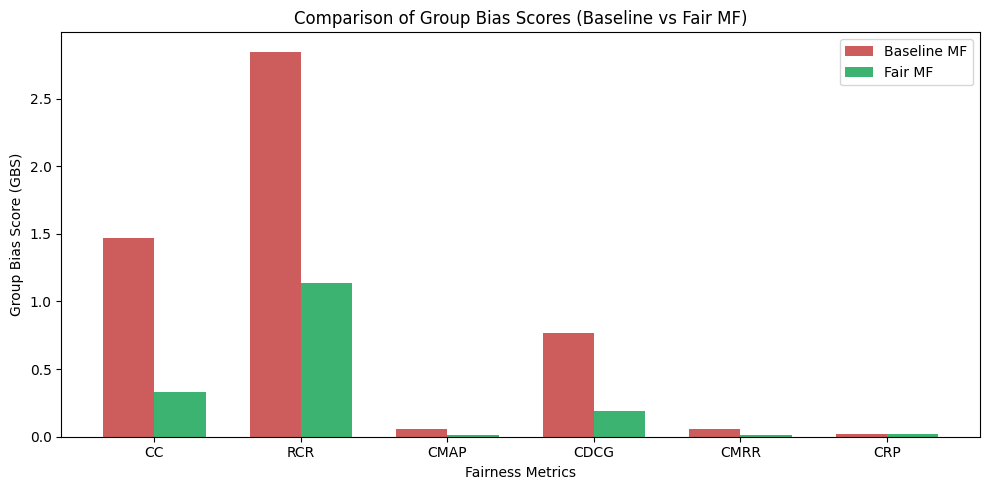

In [52]:
# ==========================================
# PHASE 6 & 7 — Evaluation of Fair MF & Comparison
# ==========================================

# 1. Generate recommendations for Fair MF model
fair_male_recs = get_user_recommendations(fair_mf, male_users, n_items)
fair_female_recs = get_user_recommendations(fair_mf, female_users, n_items)

# 2. Compute metrics for Fair MF model
fair_male_metrics = compute_fairness_metrics(fair_male_recs, item_genres, dataset_genre_props)
fair_female_metrics = compute_fairness_metrics(fair_female_recs, item_genres, dataset_genre_props)

# 3. Compute GBS Scores for Fair MF
fair_gbs = compute_gbs(fair_male_metrics, fair_female_metrics)
print("Fair MF GBS Scores:", fair_gbs)

# 4. Summary Comparison Table
comparison_df = pd.DataFrame({
    'Metric': list(baseline_gbs.keys()),
    'Baseline GBS': list(baseline_gbs.values()),
    'Fair MF GBS': list(fair_gbs.values())
})

print("\n--- Fairness Comparison (GBS: Lower is Better) ---")
print(comparison_df.to_string(index=False))

# 5. Plotting Comparison
plt.figure(figsize=(10, 5))
x = np.arange(len(baseline_gbs))
width = 0.35

plt.bar(x - width/2, list(baseline_gbs.values()), width, label='Baseline MF', color='indianred')
plt.bar(x + width/2, list(fair_gbs.values()), width, label='Fair MF', color='mediumseagreen')

plt.xlabel('Fairness Metrics')
plt.ylabel('Group Bias Score (GBS)')
plt.title('Comparison of Group Bias Scores (Baseline vs Fair MF)')
plt.xticks(x, list(baseline_gbs.keys()))
plt.legend()
plt.tight_layout()
plt.show()

Baseline MF -> Precision@10: 0.0729, NDCG@10: 0.1916, Accuracy (HitRate): 0.9476
Fair MF     -> Precision@10: 0.0762, NDCG@10: 0.1931, Accuracy (HitRate): 0.9455


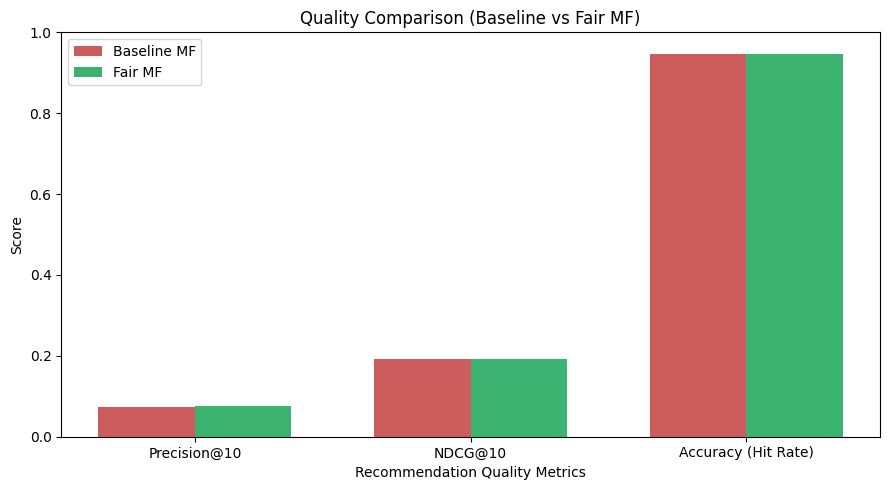

In [53]:
# ==========================================
# PHASE 8 — Recommendation Quality Metrics (Precision, NDCG, Accuracy)
# ==========================================

def compute_ranking_metrics(model, test_df, n_items, top_k=50):
    model.eval()
    
    # Ground truth positive items per user in test set
    test_user_positives = test_df[test_df['rating'] >= 3].groupby('user_idx')['item_idx'].apply(set).to_dict()
    
    precisions = []
    ndcgs = []
    hits = []
    
    all_items = torch.arange(n_items, dtype=torch.long)
    
    with torch.no_grad():
        for u, true_items in test_user_positives.items():
            if len(true_items) == 0:
                continue
            
            u_tensor = torch.tensor([u] * n_items, dtype=torch.long)
            u_e = model.user_emb(u_tensor)
            i_e = model.item_emb(all_items)
            scores = (u_e * i_e).sum(dim=-1)
            
            # Top-K recommendations
            top_indices = torch.topk(scores, top_k).indices.cpu().tolist()
            
            # Precision@K & Hit Rate (Accuracy proxy)
            hits_in_top = sum([1 for item in top_indices if item in true_items])
            precision = hits_in_top / top_k
            precisions.append(precision)
            hits.append(1 if hits_in_top > 0 else 0)
            
            # NDCG@K
            dcg = sum([1.0 / np.log2(idx + 2) for idx, item in enumerate(top_indices) if item in true_items])
            idcg = sum([1.0 / np.log2(idx + 2) for idx in range(min(len(true_items), top_k))])
            ndcg = dcg / idcg if idcg > 0 else 0.0
            ndcgs.append(ndcg)
            
    return np.mean(precisions), np.mean(ndcgs), np.mean(hits)

# Evaluate Baseline MF
base_prec, base_ndcg, base_acc = compute_ranking_metrics(baseline_mf, test_df, n_items, top_k=50)

# Evaluate Fair MF
fair_prec, fair_ndcg, fair_acc = compute_ranking_metrics(fair_mf, test_df, n_items, top_k=50)

print(f"Baseline MF -> Precision@10: {base_prec:.4f}, NDCG@10: {base_ndcg:.4f}, Accuracy (HitRate): {base_acc:.4f}")
print(f"Fair MF     -> Precision@10: {fair_prec:.4f}, NDCG@10: {fair_ndcg:.4f}, Accuracy (HitRate): {fair_acc:.4f}")

# Plotting Comparison
metrics_names = ['Precision@10', 'NDCG@10', 'Accuracy (Hit Rate)']
baseline_metrics = [base_prec, base_ndcg, base_acc]
fair_metrics = [fair_prec, fair_ndcg, fair_acc]

plt.figure(figsize=(9, 5))
x = np.arange(len(metrics_names))
width = 0.35

plt.bar(x - width/2, baseline_metrics, width, label='Baseline MF', color='indianred')
plt.bar(x + width/2, fair_metrics, width, label='Fair MF', color='mediumseagreen')

plt.xlabel('Recommendation Quality Metrics')
plt.ylabel('Score')
plt.title('Quality Comparison (Baseline vs Fair MF)')
plt.xticks(x, metrics_names)
plt.ylim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

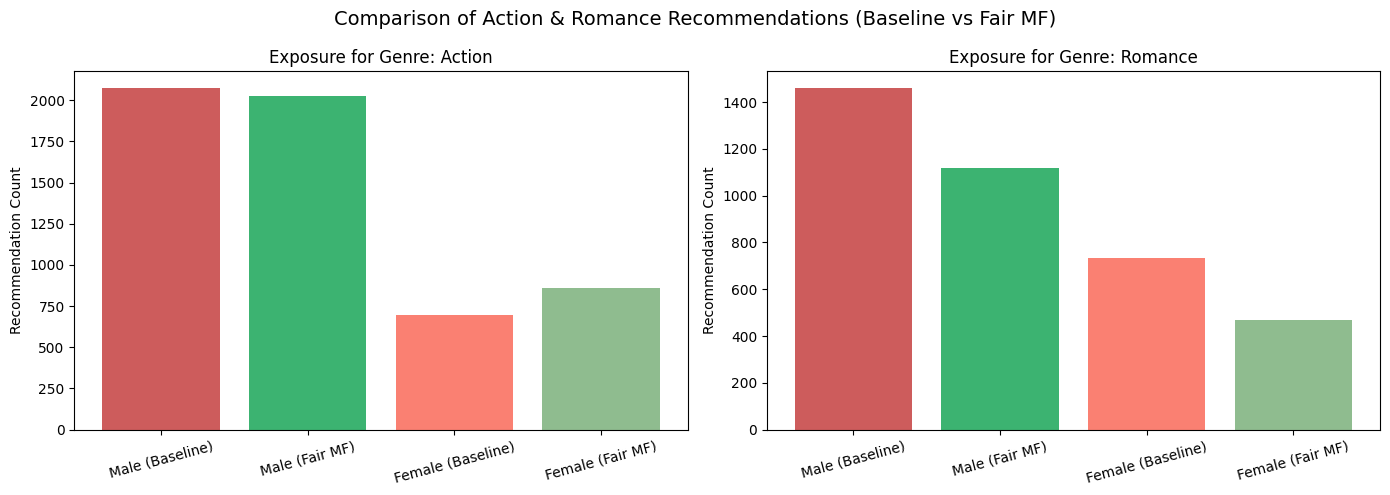

In [54]:
# ==========================================
# PHASE 9 — Genre-Specific Recommendations Plot (Action & Romance)
# ==========================================

def get_genre_exposure_by_group(user_recs, item_genres, genre_cols, target_genres=['Action', 'Romance']):
    genre_indices = [genre_cols.index(g) for g in target_genres]
    group_exposure = {g: 0 for g in target_genres}
    
    total_recs = 0
    for u, recs in user_recs.items():
        for item in recs:
            for g_idx, g_name in zip(genre_indices, target_genres):
                group_exposure[g_name] += item_genres[item, g_idx]
            total_recs += 1
            
    # Normalize by total recommendations to get proportion/count
    return group_exposure

# Calculate exposures for Action and Romance
target_genres = ['Action', 'Romance']

# Baseline exposures
base_male_exp = get_genre_exposure_by_group(male_recs, item_genres, genre_cols, target_genres)
base_female_exp = get_genre_exposure_by_group(female_recs, item_genres, genre_cols, target_genres)

# Fair MF exposures
fair_male_exp = get_genre_exposure_by_group(fair_male_recs, item_genres, genre_cols, target_genres)
fair_female_exp = get_genre_exposure_by_group(fair_female_recs, item_genres, genre_cols, target_genres)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, genre in enumerate(target_genres):
    ax = axes[idx]
    categories = ['Male (Baseline)', 'Male (Fair MF)', 'Female (Baseline)', 'Female (Fair MF)']
    values = [
        base_male_exp[genre],
        fair_male_exp[genre],
        base_female_exp[genre],
        fair_female_exp[genre]
    ]
    colors = ['indianred', 'mediumseagreen', 'salmon', 'darkseagreen']
    
    ax.bar(categories, values, color=colors)
    ax.set_title(f'Exposure for Genre: {genre}')
    ax.set_ylabel('Recommendation Count')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Comparison of Action & Romance Recommendations (Baseline vs Fair MF)', fontsize=14)
plt.tight_layout()
plt.show()